Размер датасета: (60000, 28, 28, 1)
Старт обучения WGAN-GP на 2000 эпох...
Epoch    0 | Critic Loss:   8.0169 | Generator Loss:   0.0232


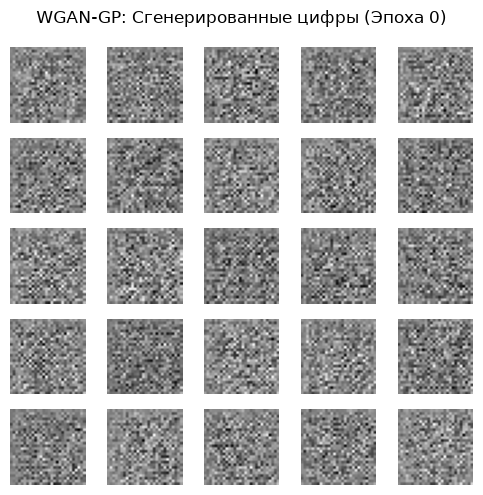

Epoch  500 | Critic Loss:  -2.4519 | Generator Loss:   1.9606


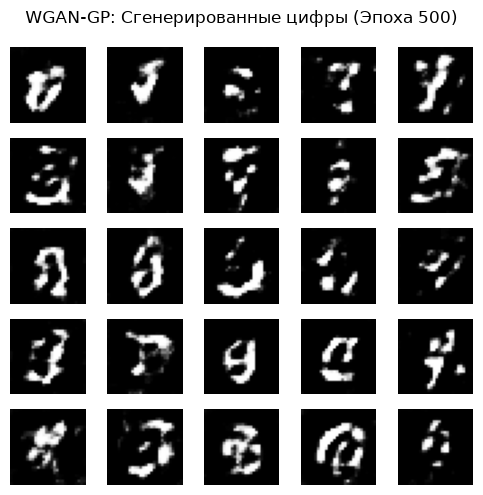

Epoch 1000 | Critic Loss:  -3.9044 | Generator Loss:   8.9716


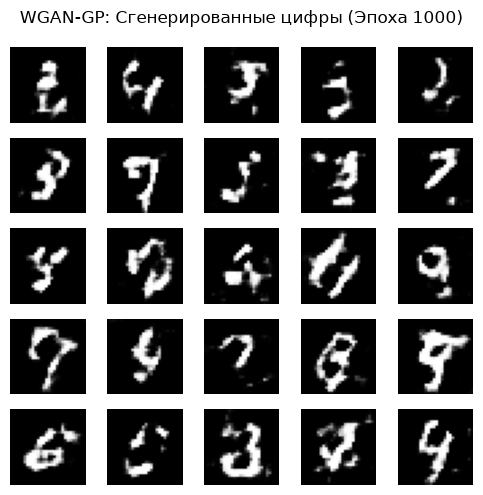

Epoch 1500 | Critic Loss:  -3.1099 | Generator Loss:  -7.9421


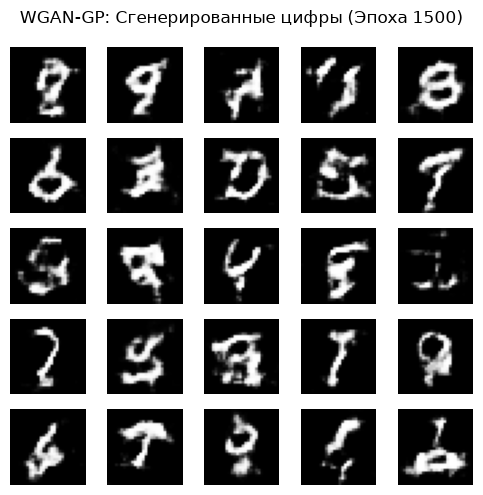

Epoch 2000 | Critic Loss:  -2.7002 | Generator Loss:  -8.5450


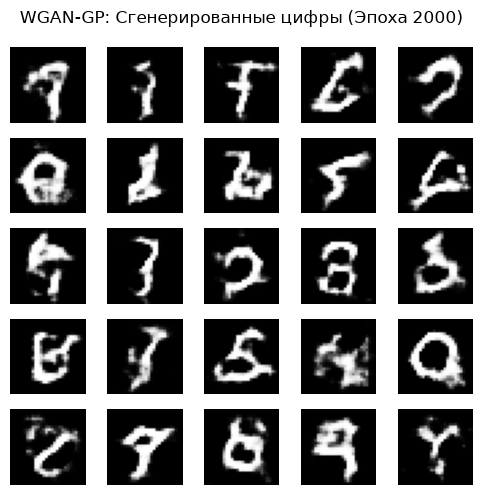

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import ( 
    Input, Dense, Reshape, Flatten, LeakyReLU,
    BatchNormalization, Conv2D, Conv2DTranspose
)
from tensorflow.keras.models import Model 
from tensorflow.keras.optimizers import Adam 
import matplotlib.pyplot as plt


(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

x_train = (x_train.astype(np.float32) - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)
print(f"Размер датасета: {x_train.shape}")


LATENT_DIM = 100
LAMBDA_GP = 10.0   
N_CRITIC = 2        
LR = 0.0002         
BATCH_SIZE = 128    
EPOCHS = 2000       


def build_generator(latent_dim=LATENT_DIM):
    noise_input = Input(shape=(latent_dim,))

    x = Dense(7 * 7 * 128, kernel_initializer='he_normal')(noise_input)
    x = Reshape((7, 7, 128))(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(negative_slope=0.2)(x)

    x = Conv2DTranspose(64, kernel_size=(5, 5), strides=(2, 2), padding='same')(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(negative_slope=0.2)(x)

    out = Conv2DTranspose(1, kernel_size=(5, 5), strides=(2, 2), padding='same', activation='tanh')(x)

    return Model(noise_input, out, name="Generator")

def build_critic():
    img_input = Input(shape=(28, 28, 1))

    x = Conv2D(64, kernel_size=(5, 5), strides=(2, 2), padding='same')(img_input)
    x = LeakyReLU(negative_slope=0.2)(x)

    x = Conv2D(128, kernel_size=(5, 5), strides=(2, 2), padding='same')(x)
    x = LeakyReLU(negative_slope=0.2)(x)

    x = Flatten()(x)
    out = Dense(1)(x)

    return Model(img_input, out, name="Critic")

generator = build_generator()
critic = build_critic()

c_optimizer = Adam(learning_rate=LR, beta_1=0.5, beta_2=0.9)
g_optimizer = Adam(learning_rate=LR, beta_1=0.5, beta_2=0.9)


def gradient_penalty(critic, real_imgs, fake_imgs):
    batch_size = tf.shape(real_imgs)[0]
    alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0, dtype=tf.float32)
    interpolated = alpha * real_imgs + (1.0 - alpha) * fake_imgs

    with tf.GradientTape() as gp_tape:
        gp_tape.watch(interpolated)
        pred = critic(interpolated, training=True)

    grads = gp_tape.gradient(pred, interpolated)
    norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=[1, 2, 3]) + 1e-12)
    gp = tf.reduce_mean((norm - 1.0) ** 2)
    return gp

@tf.function
def train_step(real_imgs):
    batch_size = tf.shape(real_imgs)[0]

    for _ in range(N_CRITIC):
        noise = tf.random.normal([batch_size, LATENT_DIM])
        with tf.GradientTape() as c_tape:
            fake_imgs = generator(noise, training=True)
            real_pred = critic(real_imgs, training=True)
            fake_pred = critic(fake_imgs, training=True)

            w_loss = tf.reduce_mean(fake_pred) - tf.reduce_mean(real_pred)
            gp = gradient_penalty(critic, real_imgs, fake_imgs)
            c_loss = w_loss + LAMBDA_GP * gp

        c_grads = c_tape.gradient(c_loss, critic.trainable_variables)
        c_optimizer.apply_gradients(zip(c_grads, critic.trainable_variables))

    noise = tf.random.normal([batch_size, LATENT_DIM])
    with tf.GradientTape() as g_tape:
        fake_imgs = generator(noise, training=True)
        fake_pred = critic(fake_imgs, training=True)
        g_loss = -tf.reduce_mean(fake_pred)

    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))

    return c_loss, g_loss

def sample_images(epoch, num_images=25):
    noise = np.random.normal(0, 1, (num_images, LATENT_DIM)).astype(np.float32)
    gen_imgs = generator(noise, training=False).numpy()
    gen_imgs = 0.5 * gen_imgs + 0.5  # Ремаппинг в [0, 1]

    fig, axs = plt.subplots(5, 5, figsize=(5, 5))
    cnt = 0
    for i in range(5):
        for j in range(5):
            axs[i, j].imshow(gen_imgs[cnt, :, :, 0], cmap='gray')
            axs[i, j].axis('off')
            cnt += 1
    plt.suptitle(f"WGAN-GP: Сгенерированные цифры (Эпоха {epoch})")
    plt.tight_layout()
    plt.show()


def train_gan(epochs=EPOCHS, batch_size=BATCH_SIZE, sample_interval=500):
    num_samples = x_train.shape[0]
    print(f"Старт обучения WGAN-GP на {epochs} эпох...")

    for epoch in range(epochs + 1):
        idx = np.random.randint(0, num_samples, batch_size)
        real_imgs = x_train[idx]

        c_loss, g_loss = train_step(real_imgs)

        if epoch % sample_interval == 0:
            print(f"Epoch {epoch:4d} | Critic Loss: {c_loss.numpy():8.4f} | Generator Loss: {g_loss.numpy():8.4f}")
            sample_images(epoch)

train_gan(epochs=2000, batch_size=BATCH_SIZE, sample_interval=500)